# 07 — Previsão do mercado

**Para que serve este notebook.** Os 10 números do painel são uma fotografia de **2025**: a classe de cada cartório sai da arrecadação média dos semestres de 2025 (D-010). Mas a arrecadação cresce todo ano, e o cartório que passa de **R$ 300 mil por semestre** sai da Classe 1 e fica obrigado pelo Prov. 227. Este notebook responde:

1. **Quanto os cartórios de MG vão arrecadar em 2026 e 2027?** (teste T2)
2. **O 2026-1, que já saiu (incompleto), confirma a previsão?** E houve uma **quebra de nível** em 2025-2?
3. **Quantos cartórios passam do limite, e o que isso faz com o universo de obrigadas, o passivo, a IS e o prêmio?** Em dois cenários: **limite fixo** e **limite corrigido pela inflação** (art. 16, § 2º, do Prov. 213).

**Como os métodos foram escolhidos.** O teste **T2** (`docs/qa/analises/testes_metodos.md`) comparou 7 métodos de previsão da arrecadação e escolheu a **tendência log-linear com efeito de semestre**, com o SARIMA para comparar. O **T3** e o notebook 05b mediram as subidas de classe; aqui elas aparecem como conferência.

**Regra:** tudo aqui é **PROJEÇÃO**, rotulada como tal, e **nenhum dos 10 números do painel muda**.

**Termos usados** (explicados onde aparecem pela primeira vez): série temporal, escala log, tendência log-linear, efeito de semestre, SARIMA, origem móvel, MAPE, MASE, viés, faixa P10–P90, salto grosseiro, quebra de nível, valor-p, intervalo de 95%, sorteio (Monte Carlo).

**Dados:** banco do pipeline (carga de 19/10/2026; regra de classe v2; cenário do STF "mantém"), premissas v2 (`config/premissas/premissas_v002.yaml`), arrecadação semestral do Justiça Aberta (2007-1 a 2026-1) e o IPCA do IBGE (até set/2026). Parâmetros em `config/analise.yaml`, seção `previsao`. Os gráficos também vão em PNG para `docs/qa/analises/`.

In [1]:
import json
import sys
import warnings
from pathlib import Path

raiz = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
sys.path.insert(0, str(raiz))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import display

from src import estado
from src.analise import classificacao as cl, config, dados, estatistica as est, graficos as g, previsao as pv
from src.motor import calcular_serventias, premissas_nivel
from src.notebooks import conectar
from src.transform.gold import carregar_insumos

warnings.filterwarnings("ignore", module="statsmodels")   # avisos de convergência do SARIMA e do Holt-Winters
g.estilo()
cfg = config()
pc, SEMENTE = cfg["previsao"], cfg["semente"]
con = conectar()
serie = dados.serie_arrecadacao(con)
y_tudo = pv.serie_mg(serie)                       # até o último semestre do banco (2026-1, incompleto)
y = y_tudo.loc[:pc["ultimo_periodo"]]             # o que o T2 usou: 2007-1 a 2025-2
ULT = y_tudo.index[-1]
sv = dados.serventias(con)
semente_premissas = estado.ler_semente()          # config/premissas/premissas_v002.yaml
cenarios = yaml.safe_load((raiz / "config/cenarios_stf.yaml").read_text(encoding="utf-8"))
limites = yaml.safe_load((raiz / "config/regras_classificacao.yaml").read_text(encoding="utf-8"))["versoes"]["v2"]["limites"]
L = limites["classe_1_max"]
t2 = json.loads((raiz / "docs/qa/analises/testes_metodos_resultados.json").read_text(encoding="utf-8"))["T2_previsao_arrecadacao_MG"]
nao_inf = int((~serie.loc[serie.periodo == ULT, "informado"]).sum())
print(f"Série: {y.index[0]} a {y.index[-1]} ({len(y)} semestres) para treinar; {ULT} só para conferência "
      f"({g.num(nao_inf)} de {g.num(len(sv))} serventias ativas não informaram). Semente: {SEMENTE}.")

Série: 2007-1 a 2025-2 (38 semestres) para treinar; 2026-1 só para conferência (57 de 2.525 serventias ativas não informaram). Semente: 20261022.


O **2026-1** já está no banco, mas **incompleto**: 57 serventias ativas ainda não tinham informado quando os dados foram coletados (carga de 19/10/2026). Por isso, como no T2, a previsão treina até **2025-2**, e o 2026-1 serve só para **conferir** a previsão. O plano pede para refazer a previsão com o 2026-1 completo, mas isso exigiria uma coleta e uma carga novas, que só o autor pode pedir. Em vez disso, a seção 4 completa o 2026-1 com uma estimativa (sensibilidade).

## 1. A série de MG e o 2026-1

**A pergunta.** Como a arrecadação de MG evoluiu, e o 2026-1 é comparável aos semestres anteriores?

**O método.** Uma **série temporal** é uma sequência de valores no tempo, aqui a arrecadação total das 2.525 serventias ativas em cada semestre (valores nominais, sem descontar a inflação). Para cada semestre mostramos também:
- quantas serventias **não informaram** (o valor delas entra como zero na soma);
- os **saltos grosseiros** (notebook 01): o semestre de uma serventia que fica **10 vezes acima ou abaixo** da mediana dos seus 4 semestres anteriores, quase sempre um erro de declaração. Exemplo: uma serventia que arrecadava R$ 13 mil por semestre e declara R$ 108 mi. O **excesso** é o valor declarado menos essa mediana;
- a série **sem os saltos**, com o valor de cada salto trocado pela mediana anterior da serventia. Ela serve só para comparar: o pipeline continua com a regra atual (a do autor ainda não foi decidida; `docs/ESTADO_ATUAL.md`).

,semestre,regra atual (R$ bi),sem saltos grosseiros (R$ bi),não informaram,saltos,excesso dos saltos,crescimento sobre o mesmo semestre do ano anterior (sem saltos)
0,2022-1,"1,72","1,72",0,6,"R$ -255,0 mil","24,7%"
1,2022-2,"2,02","2,02",0,8,"R$ -355,1 mil","18,4%"
2,2023-1,"1,84","1,84",0,6,"R$ -135,5 mil","6,8%"
3,2023-2,"2,18","2,18",0,9,"R$ -46,5 mil","8,1%"
4,2024-1,"2,03","2,03",0,12,"R$ 2,3 mi","10,7%"
5,2024-2,"2,50","2,48",0,26,"R$ 16,3 mi","13,8%"
6,2025-1,"2,38","2,38",0,13,"R$ 4,3 mi","17,0%"
7,2025-2,"3,13","2,97",0,32,"R$ 161,3 mi","19,7%"
8,2026-1,"3,20","2,87",57,44,"R$ 330,3 mi","20,9%"


,cns,municipio,situacao,classe na base,periodo,arrecadação no semestre,mediana dos 4 semestres anteriores,vezes a mediana,excesso
0,059816,São Gonçalo do Sapucaí,provida,1,2026-1,"R$ 157,4 mi","R$ 183,0 mil","859,7","R$ 157,2 mi"
1,042986,Turmalina,vaga,3,2025-2,"R$ 108,1 mi","R$ 13,0 mil","8.290,9","R$ 108,1 mi"
2,046219,Carmo do Paranaíba,vaga,1,2026-1,"R$ 94,3 mi","R$ 82,7 mil","1.140,9","R$ 94,2 mi"
3,033027,Andradas,provida,3,2025-2,"R$ 6,2 mi","R$ 62,2 mil","100,1","R$ 6,2 mi"
4,054767,Cambuí,provida,3,2026-1,"R$ 6,0 mi","R$ 34,9 mil","173,1","R$ 6,0 mi"
5,057737,São Lourenço,vaga,indeterminada,2026-1,"R$ 5,7 mi","R$ 110,6 mil","51,9","R$ 5,6 mi"


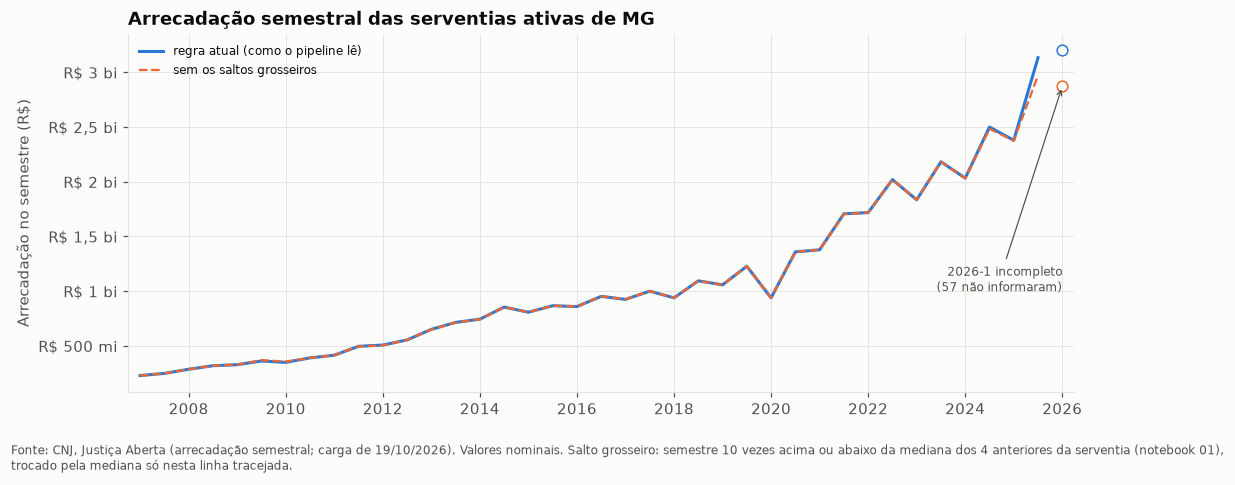

In [2]:
sal = est.saltos(serie)
sal = sal.assign(excesso=sal.arrecadacao - sal.mediana_anterior)
ss = est.sem_saltos(serie, sal)
y_ss_tudo = pv.serie_mg(ss)
rec = pd.DataFrame({"regra atual (R$ bi)": y_tudo / 1e9, "sem saltos grosseiros (R$ bi)": y_ss_tudo / 1e9})
rec["não informaram"] = serie.groupby("periodo").informado.apply(lambda v: int((~v).sum()))
rec["saltos"] = sal.groupby("periodo").size()
rec["excesso dos saltos"] = sal.groupby("periodo").excesso.sum()
rec["crescimento sobre o mesmo semestre do ano anterior (sem saltos)"] = y_ss_tudo / y_ss_tudo.shift(2) - 1
rec = rec.fillna({"saltos": 0, "excesso dos saltos": 0}).loc["2022-1":]
display(g.tabela(rec.reset_index(names="semestre"),
                 {"regra atual (R$ bi)": "num2", "sem saltos grosseiros (R$ bi)": "num2", "não informaram": "int",
                  "saltos": "int", "excesso dos saltos": "reais",
                  "crescimento sobre o mesmo semestre do ano anterior (sem saltos)": "pct"}))
maiores = (sal[sal.ano >= 2025].nlargest(6, "excesso")
           .merge(sv[["cns", "municipio", "situacao", "classe"]], on="cns", how="left"))
display(g.tabela(maiores[["cns", "municipio", "situacao", "classe", "periodo", "arrecadacao", "mediana_anterior", "razao",
                          "excesso"]],
                 {"arrecadacao": "reais", "mediana_anterior": "reais", "razao": "num1", "excesso": "reais"})
        .rename(columns={"classe": "classe na base", "arrecadacao": "arrecadação no semestre",
                         "mediana_anterior": "mediana dos 4 semestres anteriores", "razao": "vezes a mediana"}))

fig, ax = plt.subplots(figsize=(10, 4))
per = list(y_tudo.index)
x = np.arange(len(per))
ax.plot(x[:-1], y_tudo.iloc[:-1], color=g.AZUL["medio"], label="regra atual (como o pipeline lê)")
ax.plot(x[:-1], y_ss_tudo.iloc[:-1], color=g.CORES[1], linewidth=1.5, linestyle="--", label="sem os saltos grosseiros")
ax.plot(x[-1], y_tudo.iloc[-1], "o", color=g.AZUL["medio"], markerfacecolor="white", markersize=7)
ax.plot(x[-1], y_ss_tudo.iloc[-1], "o", color=g.CORES[1], markerfacecolor="white", markersize=7)
ax.annotate(f"{ULT} incompleto\n({g.num(nao_inf)} não informaram)", (x[-1], y_ss_tudo.iloc[-1]),
            xytext=(x[-1], 1.0e9), ha="right", fontsize=8, color=g.TEXTO_2,
            arrowprops={"arrowstyle": "->", "color": g.TEXTO_2, "linewidth": 0.8})
g.eixo_periodos(ax, per)
g.eixo_reais(ax)
ax.set_ylabel("Arrecadação no semestre (R$)")
ax.legend(loc="upper left", fontsize=8)
ax.set_title("Arrecadação semestral das serventias ativas de MG")
fig.tight_layout()
g.nota(fig, f"Fonte: CNJ, Justiça Aberta (arrecadação semestral; carga de 19/10/2026). Valores nominais. Salto grosseiro: semestre "
            f"{cfg['saltos']['fator']} vezes acima ou abaixo da mediana dos {cfg['saltos']['janela']} anteriores da serventia "
            "(notebook 01),\ntrocado pela mediana só nesta linha tracejada.")
g.salvar(fig, "07_serie_arrecadacao_saltos")
plt.show()

**Como ler.** Na tabela, compare as duas colunas de valor: a diferença entre elas é o peso dos saltos. No gráfico, as duas linhas só se separam no fim da série.

**O que encontramos.**
- Até 2024, os saltos pesam pouco (menos de R$ 20 mi por semestre). Em **2025-2** eles somam **R$ 161 mi** e no **2026-1, R$ 330 mi**, quase todos de três serventias: **059816** (São Gonçalo do Sapucaí, R$ 157 mi no 2026-1, 860 vezes a sua mediana), **042986** (Turmalina, R$ 108 mi no 2025-2, a já apontada no notebook 01) e **046219** (Carmo do Paranaíba, R$ 94 mi no 2026-1).
- **O 2026-1 parcial (R$ 3,20 bi) estava inflado por esses erros.** Sem os saltos, ele cai para **R$ 2,87 bi**, mesmo com 57 serventias sem informar.
- Mesmo sem os saltos, a arrecadação **acelerou**: cada semestre desde 2024-2 cresceu de 14% a 21% sobre o mesmo semestre do ano anterior, contra 7% a 11% em 2023 e no começo de 2024.

**O que significa para o Prov. 227.** A classe de uma serventia depende de um único valor declarado por semestre. Um erro de digitação de R$ 100 mi muda a classe da serventia e o total do estado. Isso reforça a proposta do notebook 01: uma checagem de saltos no pipeline.

**Limitações.** A regra do salto (10 vezes a mediana de 4 semestres) é uma suposição (`config/analise.yaml`). Ela não pega erros menores, e um crescimento real muito forte também seria marcado. Os três maiores casos, porém, são de centenas a milhares de vezes a mediana.

## 2. Teste no passado: qual método prevê melhor?

**A pergunta.** Se tivéssemos usado cada método nos anos anteriores, quanto ele teria errado?

**O método.**
- **Escala log.** Os métodos trabalham com o logaritmo da arrecadação. No log, um crescimento de 10% ao ano vira uma **reta**, e um semestre que é sempre 15% maior vira um degrau fixo.
- **Tendência log-linear com efeito de semestre (o vencedor do T2).** Ajusta, por mínimos quadrados, log(arrecadação) = a + b × t + c × (2º semestre), com t = 0, 1, 2… a contagem dos semestres. O **b** é o crescimento por semestre, e o **c** mede quanto o 2º semestre costuma ser maior (o efeito de semestre). Exemplo: com b = 0,04 e c = 0,15, cada semestre cresce e^0,04 − 1 ≈ 4,1% sobre o anterior, e o 2º semestre fica e^0,15 − 1 ≈ 16% acima da reta.
- **SARIMA (para comparar).** Modelo de séries temporais que prevê cada semestre pelas variações recentes e pela do mesmo semestre do ano anterior, com correção pelos erros passados.
- **Referência (o "chute"): repete o último semestre.** Só vale usar um método que erre menos que ela.
- **Origem móvel.** Treinamos cada método só com os dados até uma data (a **origem**: 2019-2, 2020-2, …, 2023-2) e prevemos os 4 semestres seguintes, que comparamos com o real. São 5 origens × 4 semestres = 20 previsões por método, sempre sem olhar o futuro.
- **Indicadores.** **MAPE**: o erro médio em %, sem sinal (o que decide, como no T2). Exemplo: previsões de 90 e 110 para reais de 100 dão MAPE de 10%. **MASE**: o erro médio dividido pelo erro do "sazonal ingênuo" (repetir o mesmo semestre do ano anterior) no histórico; abaixo de 1, o método é melhor que esse chute. **Viés**: o erro médio com sinal no teste do plano (treino até 2023, previsão de 2024–25); negativo = previu abaixo do real.

**Por que este método.** É o vencedor do T2, com MAPE de 7,4% contra 14,8% da referência.

,método,MAPE na origem móvel (%),MASE,MAPE treino até 2023 (%),viés 2024–25 (%),MAPE no T2,viés 2024–25 no T2,MASE no T2
0,tendência log-linear (toda a série),"7,4","0,79","4,9","-2,1","7,4","-2,1","0,52"
1,"SARIMA(0,1,1)(0,1,1)2 (log)","10,5","1,26","3,1","-2,2","10,5","-2,2","0,83"
2,Holt-Winters amortecido (log),"11,9","1,45","6,0","-6,0","11,9","-6,0","0,95"
3,referência: último semestre,"14,8","1,99","14,7","-11,0","14,8","-11,0","1,30"
4,tendência log-linear (últimos 8 semestres),"15,0","1,94","14,0","14,0","15,0","14,0","1,27"
5,sazonal + crescimento do último ano,"19,5","2,55","9,9","-9,9","19,5","-9,9","1,67"
6,sazonal ingênuo (mesmo semestre do ano anterior),"20,5","2,71","18,9","-18,9","20,5","-18,9","1,78"


Vencedor: tendência log-linear (toda a série) (no T2: tendência log-linear (toda a série)).


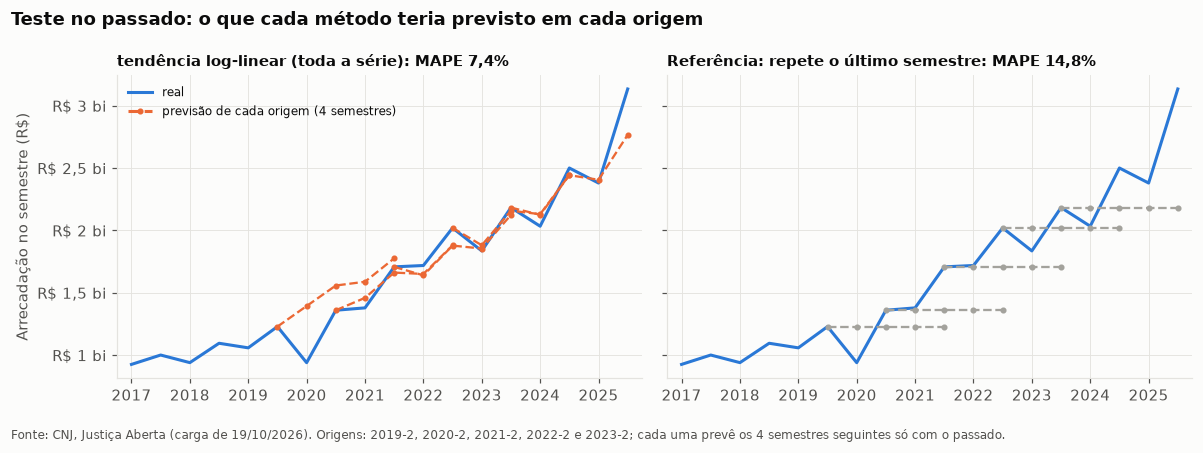

In [3]:
tab, erros = pv.origem_movel(y)
t2tab = pd.DataFrame(t2["tabela"]).set_index("metodo")
tab["MAPE no T2"] = t2tab.loc[tab.index, "MAPE_origem_movel_pct"]
tab["viés 2024–25 no T2"] = t2tab.loc[tab.index, "vies_2024_2025_pct"]
tab["MASE no T2"] = t2tab.loc[tab.index, "MASE_origem_movel"]
display(g.tabela(tab.reset_index(names="método"),
                 {"MAPE_origem_movel_pct": "num1", "MASE_origem_movel": "num2", "MAPE_teste_pct": "num1",
                  "vies_teste_pct": "num1", "MAPE no T2": "num1", "viés 2024–25 no T2": "num1", "MASE no T2": "num2"})
        .rename(columns={"MAPE_origem_movel_pct": "MAPE na origem móvel (%)", "MASE_origem_movel": "MASE",
                         "MAPE_teste_pct": "MAPE treino até 2023 (%)", "vies_teste_pct": "viés 2024–25 (%)"}))
print(f"Vencedor: {tab.index[0]} (no T2: {t2['vencedor']}).")

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
ini = list(y.index).index("2017-1")
per = list(y.index)[ini:]
for ax, metodo, cor in zip(axs, [pv.PRINCIPAL, pv.REFERENCIA], [g.CORES[1], g.CINZA]):
    ax.plot(np.arange(len(per)), y.iloc[ini:], color=g.AZUL["medio"], label="real")
    for o, e in erros[erros.metodo == metodo].groupby("origem"):
        xs = [per.index(p) for p in e.periodo]
        ax.plot([per.index(o)] + xs, [y[o]] + list(e.previsto), color=cor, linewidth=1.5, linestyle="--",
                marker="o", markersize=3)
    mape = tab.loc[metodo, "MAPE_origem_movel_pct"]
    ax.set_title(f"{metodo.replace('referência: ', 'Referência: repete o ')}: MAPE {g.num(mape, 1)}%", fontsize=10)
    g.eixo_periodos(ax, per, 1)
    g.eixo_reais(ax)
axs[0].plot([], [], color=g.CORES[1], linestyle="--", marker="o", markersize=3, label="previsão de cada origem (4 semestres)")
axs[0].legend(loc="upper left", fontsize=8)
axs[0].set_ylabel("Arrecadação no semestre (R$)")
fig.suptitle("Teste no passado: o que cada método teria previsto em cada origem", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
g.nota(fig, "Fonte: CNJ, Justiça Aberta (carga de 19/10/2026). Origens: 2019-2, 2020-2, 2021-2, 2022-2 e 2023-2; cada uma prevê os 4 "
            "semestres seguintes só com o passado.")
g.salvar(fig, "07_origem_movel_tendencia")
plt.show()

**Como ler.** Na tabela, a coluna que decide é o MAPE na origem móvel; as colunas "no T2" mostram o resultado do teste. Nos gráficos, cada linha tracejada é a previsão feita numa origem. À esquerda, as previsões da tendência acompanham o real; à direita, a referência fica "parada" enquanto a arrecadação sobe.

**O resultado bate com o do teste.** O MAPE e o viés dos 7 métodos são **iguais aos do T2** (tendência 7,4%, SARIMA 10,5%, referência 14,8%) e a ordem é a mesma. A tendência errou, em média, 7,4% a cada semestre previsto, metade do erro da referência, e no teste do plano previu 2024–25 com viés de só −2,1%.

**Correção do MASE do T2.** O MASE aqui é cerca de 1,5 vez o do T2, em todos os métodos. O script do T2 (`scripts/testes_metodos.py`) dividia pela **segunda diferença** da série (`np.diff(x, 2)`), e não pelo erro do sazonal ingênuo, como diz o comentário dele. Aqui o divisor é o do sazonal ingênuo (`previsao.origem_movel`). A ordem dos métodos e o MAPE, que é o que decide, não mudam. Com o divisor certo, a tendência fica com MASE 0,79 (abaixo de 1: melhor que o sazonal ingênuo) e a referência, com 1,99. Erro registrado em `docs/erros_ia.md`.

**Limitações.** São só 5 origens (20 previsões). A pandemia (2020-1) está dentro do teste: a origem 2019-2 errou 22% no ano seguinte, e é esse erro que alarga a faixa para baixo na seção 3.

## 3. Previsão de 2026 e 2027, com faixa

**A pergunta.** Quanto MG vai arrecadar em cada semestre de 2026 e 2027?

**O método.** A tendência é ajustada com a série inteira (2007-1 a 2025-2) e prolongada 4 semestres. A **faixa P10–P90** vem dos 20 erros da origem móvel (seção 2), como no T2. O **P10** é o valor abaixo do qual ficaram só 10% dos erros e o **P90**, o valor abaixo do qual ficaram 90%. Faixa = previsão × (1 + P10 dos erros) até previsão × (1 + P90 dos erros). Exemplo: se o P10 dos erros é −12,8% e o P90 é +7,4%, uma previsão de R$ 3,0 bi tem faixa de R$ 2,62 bi a R$ 3,22 bi. Assim, 8 em cada 10 semestres do passado ficaram dentro da faixa. Ela não é simétrica porque o passado teve mais quedas fortes (a pandemia) que altas.

In [4]:
H = pc["horizonte"]
SARIMA = "SARIMA(0,1,1)(0,1,1)2 (log)"
prev = {m: pv.prever(y, m, H) for m in [pv.PRINCIPAL, SARIMA, pv.REFERENCIA]}
faixas = {m: pv.faixa(prev[m], erros.loc[erros.metodo == m, "erro_rel"]) for m in prev}
t2prev = pd.DataFrame(t2["previsao_2026_2027_bi"], index=["p10", "central", "p90"]).T
linhas = []
for m, f in faixas.items():
    for periodo, r in f.iterrows():
        linhas.append({"método": m, "semestre": periodo, "P10": r.p10 / 1e9, "central": r.central / 1e9, "P90": r.p90 / 1e9,
                       "no T2: P10": t2prev.loc[periodo, "p10"] if m == pv.PRINCIPAL else np.nan,
                       "no T2: central": t2prev.loc[periodo, "central"] if m == pv.PRINCIPAL else np.nan,
                       "no T2: P90": t2prev.loc[periodo, "p90"] if m == pv.PRINCIPAL else np.nan})
prev_tab = pd.DataFrame(linhas)
print("Valores em R$ bilhões.")
display(g.tabela(prev_tab, {c: "num2" for c in prev_tab.columns[2:]}))
fp = faixas[pv.PRINCIPAL]
q_erros = np.quantile(erros.loc[erros.metodo == pv.PRINCIPAL, "erro_rel"], pc["faixa"])
print(f"Faixa da tendência: P10 = central × (1 − {g.num(-100 * q_erros[0], 1)}%) e P90 = central × (1 + {g.num(100 * q_erros[1], 1)}%), "
      f"pelos {int((erros.metodo == pv.PRINCIPAL).sum())} erros da origem móvel.")
print(f"Conferência {ULT} (incompleto): {g.reais(y_tudo[ULT], 2)} realizado × {g.reais(fp.loc[ULT, 'central'], 2)} previsto "
      f"(P90 {g.reais(fp.loc[ULT, 'p90'], 2)}): {g.pct(y_tudo[ULT] / fp.loc[ULT, 'central'] - 1)} acima do central.")
ano_b = pc["ano_base"]
tot = pv.totais_anuais(y)
for m in prev:
    print(f"{m}: 2026 {g.reais(pv.totais_anuais(prev[m])[ano_b + 1], 2)} ({g.pct(pv.totais_anuais(prev[m])[ano_b + 1] / tot[ano_b] - 1)} "
          f"sobre 2025); 2027 {g.reais(pv.totais_anuais(prev[m])[ano_b + 2], 2)}.")

Valores em R$ bilhões.


,método,semestre,P10,central,P90,no T2: P10,no T2: central,no T2: P90
0,tendência log-linear (toda a série),2026-1,"2,39","2,74","2,94","2,39","2,74","2,94"
1,tendência log-linear (toda a série),2026-2,"2,77","3,18","3,42","2,77","3,18","3,42"
2,tendência log-linear (toda a série),2027-1,"2,71","3,10","3,33","2,71","3,10","3,33"
3,tendência log-linear (toda a série),2027-2,"3,14","3,60","3,87","3,14","3,60","3,87"
4,"SARIMA(0,1,1)(0,1,1)2 (log)",2026-1,"2,64","2,90","3,83",—,—,—
5,"SARIMA(0,1,1)(0,1,1)2 (log)",2026-2,"3,28","3,61","4,75",—,—,—
6,"SARIMA(0,1,1)(0,1,1)2 (log)",2027-1,"3,08","3,38","4,46",—,—,—
7,"SARIMA(0,1,1)(0,1,1)2 (log)",2027-2,"3,83","4,20","5,54",—,—,—
8,referência: último semestre,2026-1,"2,91","3,13","4,37",—,—,—
9,referência: último semestre,2026-2,"2,91","3,13","4,37",—,—,—


Faixa da tendência: P10 = central × (1 − 12,8%) e P90 = central × (1 + 7,4%), pelos 20 erros da origem móvel.
Conferência 2026-1 (incompleto): R$ 3,20 bi realizado × R$ 2,74 bi previsto (P90 R$ 2,94 bi): 17,0% acima do central.
tendência log-linear (toda a série): 2026 R$ 5,92 bi (7,3% sobre 2025); 2027 R$ 6,71 bi.
SARIMA(0,1,1)(0,1,1)2 (log): 2026 R$ 6,51 bi (18,1% sobre 2025); 2027 R$ 7,59 bi.
referência: último semestre: 2026 R$ 6,27 bi (13,7% sobre 2025); 2027 R$ 6,27 bi.


**Como ler.** A faixa laranja é a da tendência (a principal), e a linha pontilhada é o SARIMA. O círculo azul é o 2026-1 parcial, e o losango, o 2026-1 sem saltos e completado (seção 4).

**O resultado bate com o do teste.** A previsão e a faixa são **as mesmas do T2** (2026-1: R$ 2,74 bi, faixa de R$ 2,39 a 2,94 bi; 2027-2: R$ 3,60 bi).

**O que encontramos.**
- Pela tendência, MG arrecada **R$ 5,92 bi em 2026** (+7,3% sobre 2025) e **R$ 6,71 bi em 2027**. O SARIMA prevê mais (R$ 6,51 bi em 2026, +18%), porque dá mais peso ao salto recente.
- **Conferência do 2026-1:** o realizado parcial (R$ 3,20 bi) fica 17% acima do central e acima do P90, como o T2 já tinha apontado. A seção 4 mostra que a maior parte disso são saltos grosseiros.

**Limitações.** Valores nominais. A tendência supõe que o crescimento médio de 2007 a 2025 continua, sem mudanças de tabela de emolumentos nem de lei. A faixa só cobre erros do tamanho dos que já aconteceram de 2020 a 2025.

## 4. Saltos grosseiros e quebra de nível em 2025-2

**A pergunta.** A arrecadação mudou de patamar em 2025-2 (uma **quebra de nível**), ou o 2026-1 acima da faixa é efeito de erros de declaração?

**O método.**
- **Série sem saltos.** A mesma tendência, com a série sem os saltos grosseiros (seção 1).
- **2026-1 completado (sensibilidade).** Cada uma das 57 serventias que não informaram recebe o próprio 2025-1 multiplicado pelo crescimento de quem informou os dois semestres. A regra é uma suposição (`config/analise.yaml`, `previsao.completar_com`).
- **Teste da quebra.** Acrescentamos à tendência um degrau que vale 0 até 2025-1 e 1 de 2025-2 em diante: log(arrecadação) = a + b × t + c × (2º semestre) + d × (depois da quebra). O **d** é o tamanho do degrau. O **intervalo de 95%** é a faixa de valores de d compatíveis com os dados. O **valor-p** é a chance de ver um degrau desse tamanho só por acaso, se não houvesse quebra: abaixo de 0,05, a quebra é considerada real. Exemplo: um degrau de +8% com valor-p de 0,37 aconteceria por acaso em 37% das vezes, então não dá para afirmar que houve quebra.
- O plano pede para testar a quebra com a regra atual e mostrá-la como **sensibilidade**, já que o autor ainda não decidiu a regra do salto grosseiro.

Completar o 2026-1: 57 serventias sem informação recebem o próprio 2025-1 × 1,201 (o crescimento de quem informou os dois): + R$ 31,8 mi. 2026-1 sem saltos e completado: R$ 2,90 bi.


,teste,salto de nível a partir de 2025-2,IC 95%,valor-p
0,"regra atual, até 2025-2 (1 semestre depois da ...","13,4%","-9,7% a 42,4%","0,27"
1,sem saltos grosseiros e com o 2026-1 completad...,"7,6%","-8,7% a 26,7%","0,37"


Valores em R$ bilhões. Realizado do 2026-1: incompleto na regra atual; sem saltos e completado nas outras duas.


,variante,semestre,p10,central,p90,realizado
0,"tendência do T2, regra atual (principal)",2026-1,"2,39","2,74","2,94","3,20"
1,"tendência do T2, regra atual (principal)",2026-2,"2,77","3,18","3,42",—
2,"tendência do T2, regra atual (principal)",2027-1,"2,71","3,10","3,33",—
3,"tendência do T2, regra atual (principal)",2027-2,"3,14","3,60","3,87",—
4,"tendência do T2, sem saltos grosseiros",2026-1,"2,38","2,72","2,93","2,90"
5,"tendência do T2, sem saltos grosseiros",2026-2,"2,75","3,15","3,39",—
6,"tendência do T2, sem saltos grosseiros",2027-1,"2,69","3,08","3,32",—
7,"tendência do T2, sem saltos grosseiros",2027-2,"3,12","3,57","3,84",—
8,"quebra de nível em 2025-2, sem saltos e com o ...",2026-2,"2,93","3,36","3,61",—
9,"quebra de nível em 2025-2, sem saltos e com o ...",2027-1,"2,87","3,29","3,54",—


MAPE na origem móvel sem os saltos: 7,1% (com a regra atual: 7,4%).
Conferência do 2026-1 sem saltos e completado: R$ 2,90 bi × previsto sem saltos R$ 2,72 bi (P10–P90: R$ 2,38 bi a R$ 2,93 bi): 6,7% acima do central.


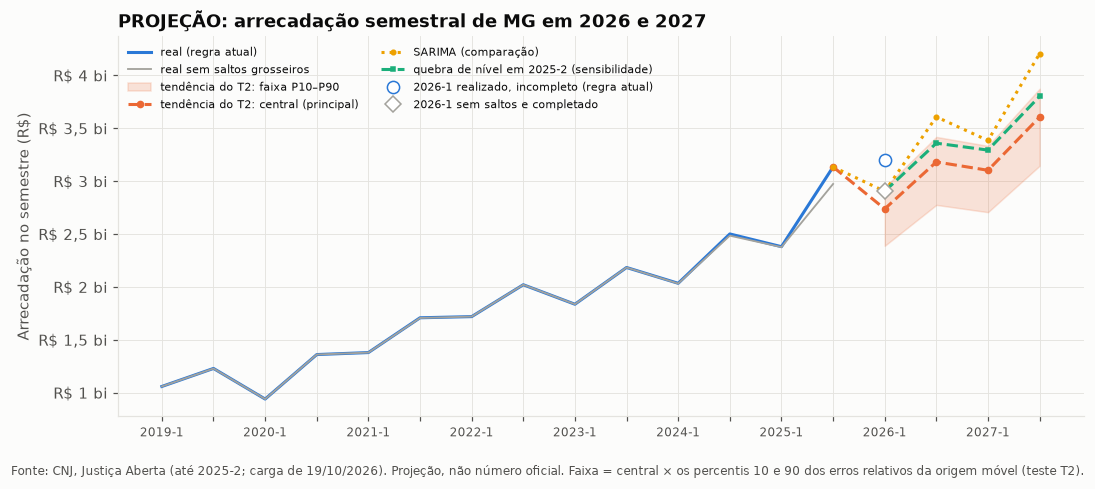

In [5]:
comp, info_c = pv.completar_semestre(ss, ULT, pc["completar_com"])
y_c = pv.serie_mg(comp)
y_ss = y_ss_tudo.loc[:pc["ultimo_periodo"]]
tab_ss, err_ss = pv.origem_movel(y_ss, {pv.PRINCIPAL: pv.METODOS[pv.PRINCIPAL]})
f_ss = pv.faixa(pv.prever(y_ss, pv.PRINCIPAL, H), err_ss.erro_rel)
q0 = pv.quebra_de_nivel(y, pc["quebra"])
q = pv.quebra_de_nivel(y_c, pc["quebra"])
prev_q = pv.prever(y_c, q["funcao"], H - 1)          # 2026-2 a 2027-2: o 2026-1 completado já entra no ajuste
f_q = pv.faixa(prev_q, erros.loc[erros.metodo == pv.PRINCIPAL, "erro_rel"])
print(f"Completar o {ULT}: {info_c['serventias']} serventias sem informação recebem o próprio {pc['completar_com']} × "
      f"{g.num(info_c['crescimento'], 3)} (o crescimento de quem informou os dois): + {g.reais(info_c['acrescimo'])}. "
      f"{ULT} sem saltos e completado: {g.reais(y_c[ULT], 2)}.")
qs = pd.DataFrame([
    {"teste": f"regra atual, até {pc['ultimo_periodo']} ({q0['semestres_depois']} semestre depois da quebra)", **q0},
    {"teste": f"sem saltos grosseiros e com o {ULT} completado ({q['semestres_depois']} semestres depois)", **q}])
qs["IC 95%"] = [f"{g.pct(a)} a {g.pct(b)}" for a, b in qs.ic95]
display(g.tabela(qs[["teste", "salto", "IC 95%", "valor_p"]], {"salto": "pct", "valor_p": "num2"})
        .rename(columns={"salto": f"salto de nível a partir de {pc['quebra']}", "valor_p": "valor-p"}))
var = pd.concat({"tendência do T2, regra atual (principal)": fp,
                 "tendência do T2, sem saltos grosseiros": f_ss,
                 f"quebra de nível em {pc['quebra']}, sem saltos e com o {ULT} completado": f_q}, names=["variante", "semestre"])
var = var.reset_index()
var["realizado"] = [(y_tudo[ULT] if v.endswith("(principal)") else y_c[ULT]) if s == ULT else np.nan
                    for v, s in zip(var.variante, var.semestre)]
print("Valores em R$ bilhões. Realizado do 2026-1: incompleto na regra atual; sem saltos e completado nas outras duas.")
display(g.tabela(var.assign(**{c: var[c] / 1e9 for c in ["p10", "central", "p90", "realizado"]}),
                 {"p10": "num2", "central": "num2", "p90": "num2", "realizado": "num2"}))
print(f"MAPE na origem móvel sem os saltos: {g.num(tab_ss.iloc[0].MAPE_origem_movel_pct, 1)}% "
      f"(com a regra atual: {g.num(tab.loc[pv.PRINCIPAL, 'MAPE_origem_movel_pct'], 1)}%).")
print(f"Conferência do {ULT} sem saltos e completado: {g.reais(y_c[ULT], 2)} × previsto sem saltos {g.reais(f_ss.loc[ULT, 'central'], 2)} "
      f"(P10–P90: {g.reais(f_ss.loc[ULT, 'p10'], 2)} a {g.reais(f_ss.loc[ULT, 'p90'], 2)}): "
      f"{g.pct(y_c[ULT] / f_ss.loc[ULT, 'central'] - 1)} acima do central.")

fig, ax = plt.subplots(figsize=(10, 4.2))
ini = list(y_tudo.index).index("2019-1")
per = list(y_tudo.index)[ini:] + list(fp.index[1:])
xp = {p: i for i, p in enumerate(per)}
ax.plot([xp[p] for p in y.index[ini:]], y.iloc[ini:], color=g.AZUL["medio"], label="real (regra atual)")
ax.plot([xp[p] for p in y_ss.index[ini:]], y_ss.iloc[ini:], color=g.CINZA, linewidth=1.2, label="real sem saltos grosseiros")
xf = [xp[y.index[-1]]] + [xp[p] for p in fp.index]
ax.fill_between(xf[1:], fp.p10, fp.p90, color=g.CORES[1], alpha=0.18, label="tendência do T2: faixa P10–P90")
ax.plot(xf, [y.iloc[-1]] + list(fp.central), color=g.CORES[1], linestyle="--", marker="o", markersize=4,
        label="tendência do T2: central (principal)")
ax.plot(xf, [y.iloc[-1]] + list(faixas[SARIMA].central), color=g.CORES[3], linestyle=":", marker="o", markersize=3,
        label="SARIMA (comparação)")
xq = [xp[ULT]] + [xp[p] for p in prev_q.index]
ax.plot(xq, [y_c[ULT]] + list(prev_q), color=g.CORES[2], linestyle="--", marker="s", markersize=3,
        label=f"quebra de nível em {pc['quebra']} (sensibilidade)")
ax.plot(xp[ULT], y_tudo[ULT], "o", color=g.AZUL["medio"], markerfacecolor="white", markersize=8,
        label=f"{ULT} realizado, incompleto (regra atual)")
ax.plot(xp[ULT], y_c[ULT], "D", color=g.CINZA, markerfacecolor="white", markersize=7,
        label=f"{ULT} sem saltos e completado")
ax.set_xticks(range(len(per)), [p if p.endswith("-1") else "" for p in per], fontsize=8)
g.eixo_reais(ax)
ax.set_ylabel("Arrecadação no semestre (R$)")
ax.legend(loc="upper left", fontsize=7.5, ncol=2)
ax.set_title("PROJEÇÃO: arrecadação semestral de MG em 2026 e 2027")
fig.tight_layout()
g.nota(fig, f"Fonte: CNJ, Justiça Aberta (até {pc['ultimo_periodo']}; carga de 19/10/2026). Projeção, não número oficial. Faixa = central × "
            "os percentis 10 e 90 dos erros relativos da origem móvel (teste T2).")
g.salvar(fig, "07_previsao_arrecadacao_2026_2027")
plt.show()

**Como ler.** A primeira tabela traz o teste da quebra; a segunda, a previsão de cada variante, com o 2026-1 realizado na coluna da direita.

**O que encontramos.**
- **Não há evidência de quebra.** Com a regra atual (só o 2025-2 depois da quebra), o degrau estimado é de +13%, com valor-p de 0,27. Sem os saltos e com o 2026-1 completado, cai para **+7,6%**, com intervalo de 95% de −8,7% a +26,7% e valor-p de 0,37.
- **O 2026-1 sem saltos e completado (R$ 2,90 bi) fica dentro da faixa** da tendência sem saltos (R$ 2,38 a 2,93 bi), 6,7% acima do central. A maior parte do "2026-1 acima do P90" do T2 vinha de três semestres com erro de declaração.
- Tirar os saltos quase não muda o passado (MAPE de 7,1% contra 7,4%) nem a previsão (R$ 2,72 bi contra R$ 2,74 bi para o 2026-1).
- A variante **com quebra** prevê cerca de 6% a mais em cada semestre (2027-2: R$ 3,80 bi contra R$ 3,60 bi). Ela fica como sensibilidade na projeção do mercado (seção 6).

**O que significa para o Prov. 227.** A previsão principal (a tendência do T2, regra atual) continua válida. Mesmo assim, o 2026-1 limpo ficou acima do central, e a aceleração da seção 1 é real. Se o 2026-2 também vier acima, a quebra pode virar a previsão principal.

**Limitações.** Com 1 ou 2 semestres depois da quebra, o teste tem pouco poder: uma quebra de 10% poderia existir sem aparecer como significativa. O teste deve ser refeito com o 2026-1 completo e com o 2026-2.

## 5. Do total de MG para cada serventia

**A pergunta.** A previsão é do total do estado, mas a classe é de cada serventia. Como saber quantas passam de R$ 300 mil?

**O método.** Cada serventia recebe uma receita projetada:

receita projetada = receita de 2025 × crescimento de MG × e^(desvio da serventia).

- **Crescimento de MG** = arrecadação prevista do ano ÷ arrecadação de 2025 (soma dos 2 semestres).
- **Desvio da serventia:** quanto uma serventia cresce acima ou abaixo do estado. Ele é **sorteado** da lista de desvios reais do passado: log(crescimento da serventia) − log(crescimento de MG), nos 6 anos mais recentes com resposta. A lista usa só serventias **entre R$ 100 mil e R$ 900 mil** no ano-base (um terço e o triplo do limite), que são as que podem cruzá-lo, e deixa de fora as que tiveram salto grosseiro. Exemplo: num ano em que MG cresce 20%, uma serventia que passa de R$ 280 mil para R$ 350 mil cresce 25%, e o seu desvio é log(1,25) − log(1,20) ≈ +0,04. Se esse desvio for sorteado em 2026 para uma serventia com R$ 280 mil em 2025, com MG crescendo 7,3%, ela fica com 280 mil × 1,073 × e^0,04 ≈ R$ 313 mil e passa do limite.
- **Sorteios (Monte Carlo).** O sorteio é repetido 500 vezes (semente fixa). O **central** usa o crescimento central de MG; a **faixa P10–P90** também sorteia o crescimento de MG, com um dos erros anuais da origem móvel (seção 2).

**Por que este método.** O 05b já projeta as **subidas** (quem está abaixo e passa do limite), mas o universo também depende das **descidas** e das mudanças entre as Classes 2 e 3, e precisa ser coerente com a previsão de MG. A projeção por serventia faz tudo isso e usa as funções do modelo (seção 6). Ela não estava no T2 nem no T3, por isso passa pelo próprio **teste no passado** abaixo, com a referência **"repete a contagem do ano-base"**.

**Teste no passado.** Para cada ano-base de 2019 a 2024, usando só o que se sabia no fim dele (a tendência treinada até o 2º semestre, os erros de origens anteriores e os desvios de anos anteriores), projetamos quantas serventias ficam acima do limite 1 e 2 anos depois e comparamos com o real. Para separar as duas fontes de erro, a coluna "com o fator real de MG" refaz a conta com o crescimento de MG que de fato aconteceu.

,horizonte,casos,anos-base,P10,mediana,P90
0,1 ano(s) à frente,7.158,2019–2024,"-24,8%","-1,1%","31,7%"
1,2 ano(s) à frente,6.879,2018–2023,"-31,0%","-1,2%","42,2%"


,ano_base,ano,anos à frente,serventias,acima: real,acima: referência,acima: projeção,P10,P90,acima: com o fator real de MG,subidas: real,subidas: projeção,fator de MG previsto,fator de MG real
0,2019,2020,1,2.475,713,693,841,718,867,701,64,156,"1,291","1,005"
1,2019,2021,2,2.470,877,692,917,756,879,865,208,235,"1,471","1,350"
2,2020,2021,1,2.470,878,713,878,761,828,871,179,171,"1,358","1,343"
3,2020,2022,2,2.457,982,713,954,779,848,988,274,249,"1,536","1,626"
4,2021,2022,1,2.464,983,878,958,805,876,998,124,103,"1,140","1,211"
5,2021,2023,2,2.463,1.050,878,1.040,852,986,1.047,195,183,"1,289","1,302"
6,2022,2023,1,2.470,1.057,990,1.044,888,1.033,1.040,96,87,"1,080","1,075"
7,2022,2024,2,2.461,1.147,989,1.123,933,1.163,1.118,184,163,"1,224","1,213"
8,2023,2024,1,2.462,1.147,1.056,1.137,980,1.173,1.131,124,105,"1,137","1,128"
9,2023,2025,2,2.425,1.280,1.046,1.202,1.017,1.236,1.244,257,179,"1,287","1,372"


,anos à frente,projeção (central),referência: repete o ano-base,diagnóstico: com o fator real de MG,viés da projeção,faixa P10–P90 contém o real,viés das subidas
0,1,"39,7","99,0","14,5","3,0","16,7%","-4,2"
1,2,"36,0","203,6","17,2","-20,0","40,0%","-21,8"


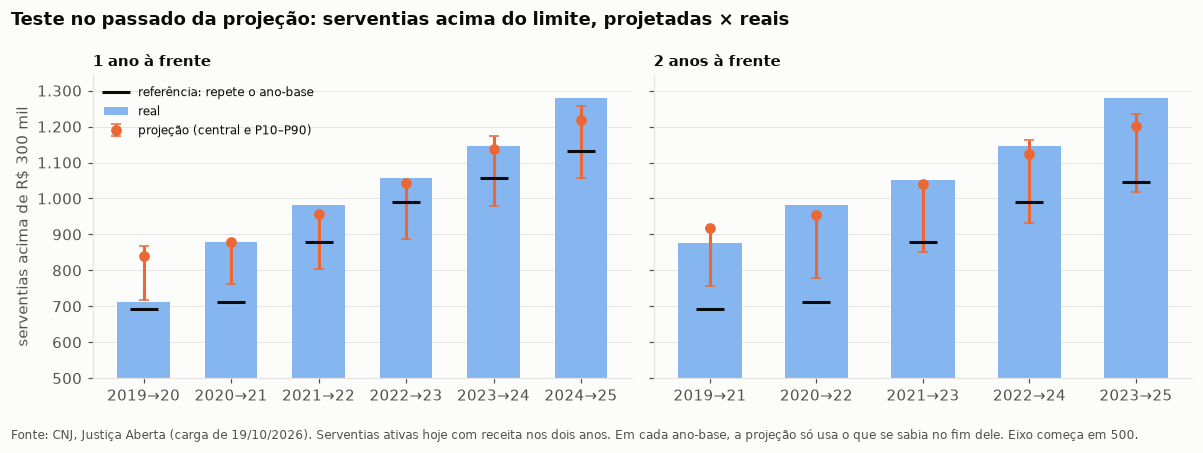

In [6]:
media, maximo = cl.receita_anual(serie)
ano_b = pc["ano_base"]
dsv = {h: pv.desvios_individuais(media, sal, list(range(ano_b - h - pc["desvios"]["anos"] + 1, ano_b - h + 1)), h, L)
       for h in (1, 2)}
resumo_d = pd.DataFrame({f"{h} ano(s) à frente": {"casos": len(d), "anos-base": f"{d.ano_base.min()}–{d.ano_base.max()}",
                                                  "P10": np.exp(d.desvio.quantile(0.1)) - 1, "mediana": np.exp(d.desvio.median()) - 1,
                                                  "P90": np.exp(d.desvio.quantile(0.9)) - 1}
                         for h, d in dsv.items()}).T
display(g.tabela(resumo_d.reset_index(names="horizonte"), {"casos": "int", "P10": "pct", "mediana": "pct", "P90": "pct"}))

anos_bt = list(range(int(pc["origens"][0][:4]), ano_b))
bt = pv.teste_contagem(y, media, sal, anos_bt, L)
display(g.tabela(bt[["ano_base", "ano", "h", "serventias", "acima_real", "acima_referencia", "acima_central", "acima_p10",
                     "acima_p90", "acima_central_fator_real", "subidas_real", "subidas_central", "fator_mg", "fator_mg_real"]],
                 {"serventias": "int", "acima_real": "int", "acima_referencia": "int", "acima_central": "int", "acima_p10": "int",
                  "acima_p90": "int", "acima_central_fator_real": "int", "subidas_real": "int", "subidas_central": "int",
                  "fator_mg": "num3", "fator_mg_real": "num3"})
        .rename(columns={"h": "anos à frente", "acima_real": "acima: real", "acima_referencia": "acima: referência",
                         "acima_central": "acima: projeção", "acima_p10": "P10", "acima_p90": "P90",
                         "acima_central_fator_real": "acima: com o fator real de MG", "subidas_real": "subidas: real",
                         "subidas_central": "subidas: projeção", "fator_mg": "fator de MG previsto",
                         "fator_mg_real": "fator de MG real"}))
err_bt = pd.DataFrame({
    "projeção (central)": (bt.acima_central - bt.acima_real).abs(),
    "referência: repete o ano-base": (bt.acima_referencia - bt.acima_real).abs(),
    "diagnóstico: com o fator real de MG": (bt.acima_central_fator_real - bt.acima_real).abs(),
    "viés da projeção": bt.acima_central - bt.acima_real, "h": bt.h}).groupby("h").mean()
err_bt["faixa P10–P90 contém o real"] = bt.groupby("h").dentro_da_faixa.mean()
err_bt["viés das subidas"] = (bt.subidas_central - bt.subidas_real).groupby(bt.h).mean()
display(g.tabela(err_bt.reset_index(names="anos à frente"),
                 {c: "num1" for c in err_bt.columns if c != "faixa P10–P90 contém o real"} | {"faixa P10–P90 contém o real": "pct"}))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for ax, h in zip(axs, (1, 2)):
    b = bt[bt.h == h]
    xs = np.arange(len(b))
    ax.bar(xs, b.acima_real, color=g.AZUL["claro"], width=0.6, label="real")
    ax.errorbar(xs, b.acima_central, yerr=[(b.acima_central - b.acima_p10).clip(lower=0), (b.acima_p90 - b.acima_central).clip(lower=0)],
                fmt="o", color=g.CORES[1], capsize=3, label="projeção (central e P10–P90)")
    ax.plot(xs, b.acima_referencia, "_", color=g.TEXTO, markersize=18, markeredgewidth=2, label="referência: repete o ano-base")
    ax.set_xticks(xs, [f"{a}→{str(c)[2:]}" for a, c in zip(b.ano_base, b.ano)])
    ax.set_title(f"{h} ano{'s' if h > 1 else ''} à frente", fontsize=10)
    ax.set_ylim(500, None)
    ax.grid(axis="x", visible=False)
    g.eixo_num(ax)
axs[0].set_ylabel(f"serventias acima de {g.reais(L, 0)}")
axs[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Teste no passado da projeção: serventias acima do limite, projetadas × reais", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
g.nota(fig, "Fonte: CNJ, Justiça Aberta (carga de 19/10/2026). Serventias ativas hoje com receita nos dois anos. Em cada ano-base, "
            "a projeção só usa o que se sabia no fim dele. Eixo começa em 500.")
g.salvar(fig, "07_teste_contagem_acima_do_limite")
plt.show()

**Como ler.** Na primeira tabela, a dispersão dos desvios: 8 em cada 10 serventias ficaram entre 25% abaixo e 32% acima do crescimento de MG num ano. Na segunda, cada linha é um ano-base. No gráfico, a barra é o real, o ponto laranja é a projeção (com a faixa) e o traço preto é a referência.

**O que encontramos.**
- A projeção **erra bem menos que a referência**: em média, **40 serventias** a 1 ano (referência: 99) e **36 a 2 anos** (referência: 204).
- Com o crescimento real de MG, o erro cai para **15 e 17 serventias**. Ou seja, a **passagem do total para cada serventia funciona**, e o que mais erra é a previsão de MG. O pior caso é o de 2019: a tendência previu +29% para 2020, e a pandemia trouxe +0,5%.
- **A faixa P10–P90 é estreita demais:** contém o real em só 17% dos casos a 1 ano e 40% a 2 anos (o certo seriam 80%). Nos anos-base mais antigos, os erros anuais vêm de origens em que a tendência errava muito para cima (2013 a 2017), e a faixa fica deslocada para baixo. Para 2026 e 2027, os erros vêm das origens de 2019-2 a 2023-2, quase sem viés, mas a faixa deve ser lida como **aproximada**.
- As **subidas** saem um pouco abaixo do real (viés de −4 a 1 ano e de −22 a 2 anos). É o mesmo sentido do T3: todos os métodos subestimam as subidas.

**Limitações.** O teste usa as serventias ativas hoje (as que fecharam não entram), e a contagem é sobre todas as situações, porque a situação jurídica de cada ano não está no banco. O desvio sorteado não depende do porte nem da atribuição da serventia, dentro da banda.

## 6. Projeção do universo, do passivo, da IS e do prêmio

**A pergunta.** Com a receita de 2026 e de 2027, quantas serventias ficam obrigadas, e quanto vale o mercado?

**O método.**
- Para cada sorteio da seção 5, a receita de referência de cada serventia é trocada pela projetada e o modelo é refeito com as **funções do modelo**: classe e universo (`universo`), peso das serventias de classe indeterminada recalculado como no pipeline e prêmio por `simulador.resumo_por_totais`, no nível base. A primeira linha abaixo confere que, sem mudar a receita, o resultado é o do painel.
- **Passivo fixo no de 2025.** O passivo de cada serventia não depende da receita (rateio por empregados do CNJ, D-005) e fica o da RAIS 2025. Só muda **quem** está no universo. Não projetamos salários nem contratações, porque não há fonte para isso.
- **Dois cenários do limite:**
  - **limite fixo:** R$ 300 mil e R$ 1,5 mi, como no Prov. 243;
  - **limite corrigido pelo IPCA:** os dois limites corrigidos todo ano (art. 16, § 2º, do Prov. 213). A redação do Prov. 243 manda atualizar "a cada ano de vigência" e deixa a divulgação com a Corregedoria Nacional, sem dizer o índice; a redação original dizia IPCA. Usamos o **IPCA dos últimos 12 meses do banco** (até set/2026), repetido em 2027: `fonte: suposição`, porque a inflação futura não está em nenhuma fonte do projeto.
- **Duas variantes da previsão de MG:** a tendência do T2 (**principal**) e a quebra de nível em 2025-2 (**sensibilidade**, seção 4).
- **Ano = ano da receita.** A classe calculada com a receita de 2026 vale para 2027 (art. 16, § 1º).
- **Regra dos dois ciclos (§ 3º).** Pelo art. 16, § 3º, a mudança de classe só vale na hora se a receita passar o limite em mais de 10%; senão, precisa se repetir no ciclo seguinte. O modelo do painel não aplica essa regra; aqui contamos quantas subidas ficam nessa zona.

In [7]:
peso = con.execute("SELECT peso_classe_indeterminada_base FROM gold.execucao WHERE regra_classe = 'v2'").fetchone()[0]
p = premissas_nivel(semente_premissas, "base", peso)
ins = carregar_insumos(con)
serv0 = calcular_serventias(ins, p, limites, limites_faixa=limites)[0]
base = pv.mercado(serv0, serv0.receita_ref.to_numpy(), limites, semente_premissas, cenarios)
oficial = con.execute("""SELECT n_universo, mercado_premio_emitido FROM gold.fato_mercado_uf
    WHERE nivel = 'base' AND regra_classe = 'v2' AND cenario_stf = 'mantem'""").df().iloc[0]
inflacao, mes_ipca = pv.inflacao_recente(dados.indice_preco(con, "IPCA"))
print(f"Base (2025) pelas funções do modelo: {g.num(base['n_universo'], 1)} obrigadas, prêmio {g.reais(base['mercado_premio_emitido'])} "
      f"(painel: {g.num(oficial.n_universo, 1)} e {g.reais(oficial.mercado_premio_emitido)}).")
print(f"IPCA dos 12 meses até {mes_ipca % 100:02d}/{mes_ipca // 100}: {g.pct(inflacao, 2)} → limite da Classe 1 corrigido: "
      + ", ".join(f"{a}: {g.reais(pv.limites_corrigidos(limites, inflacao, a - ano_b)['classe_1_max'], 1)}" for a in pc["anos"]) + ".")

ea = pv.erros_anuais(erros, pv.PRINCIPAL)
FAT = {"tendência do T2 (principal)": pv.fatores_ano(prev[pv.PRINCIPAL], y, ano_b),
       f"quebra de nível em {pc['quebra']} (sensibilidade)": pv.fatores_ano(pd.concat([y_c.loc[ULT:], prev_q]), y_c, ano_b)}
display(g.tabela(pd.DataFrame(FAT).T.reset_index(names="variante"), {a: "num3" for a in pc["anos"]}))
MEDIDAS = ["acima_do_limite", "providas_acima", "subidas", "descidas", "subidas_ate_consolidacao", "classe_2_para_3",
           "n_universo", "passivo_universo", "valor_descoberto", "mercado_importancia_segurada", "mercado_premio_emitido"]
rng = np.random.default_rng(SEMENTE)
N = pc["sorteios"]
linhas, guarda = [], {}
for ano in pc["anos"]:
    h = ano - ano_b
    d = dsv[h].desvio.to_numpy()
    e = ea.loc[ea.ano_frente == h, "erro_rel"].to_numpy()
    for variante, fat in FAT.items():
        rec_c = pv.sortear_receitas(serv0.receita_ref, np.full(N, fat[ano]), d, rng)
        rec_f = pv.sortear_receitas(serv0.receita_ref, pv.sortear_fatores(float(fat[ano]), e, N, rng), d, rng)
        for cen_lim, lim_ in [("limite fixo", limites), ("limite corrigido pelo IPCA", pv.limites_corrigidos(limites, inflacao, h))]:
            c = pv.projetar_mercado(serv0, rec_c, lim_, semente_premissas, cenarios)
            f = pv.projetar_mercado(serv0, rec_f, lim_, semente_premissas, cenarios)
            guarda[(ano, variante, cen_lim)] = f
            for m in MEDIDAS:
                linhas.append({"ano": ano, "variante": variante, "cenario_limite": cen_lim, "medida": m,
                               "p10": f[m].quantile(pc["faixa"][0]), "central": c[m].median(), "p90": f[m].quantile(pc["faixa"][1])})
proj = pd.DataFrame(linhas)

def faixa_txt(r, fmt):
    return f"{fmt(r.central)} ({fmt(r.p10)} a {fmt(r.p90)})"

FMT = {m: g.num for m in MEDIDAS[:7]} | {m: g.reais for m in MEDIDAS[7:]}
ROT = {"acima_do_limite": "acima do limite (todas)", "providas_acima": "providas acima do limite",
       "subidas": "subidas desde 2025", "descidas": "descidas desde 2025",
       "subidas_ate_consolidacao": "subidas até 10% acima (§ 3º)", "classe_2_para_3": "da Classe 2 para a 3",
       "n_universo": "obrigadas (universo)", "passivo_universo": "passivo das obrigadas", "valor_descoberto": "déficit",
       "mercado_importancia_segurada": "IS", "mercado_premio_emitido": "prêmio anual"}
for v in FAT:
    t = pd.DataFrame({"base 2025 (painel)": [FMT[m](base[m]) for m in MEDIDAS]}, index=[ROT[m] for m in MEDIDAS])
    for cen_lim in ("limite fixo", "limite corrigido pelo IPCA"):
        for ano in pc["anos"]:
            r = proj[(proj.variante == v) & (proj.cenario_limite == cen_lim) & (proj.ano == ano)].set_index("medida").loc[MEDIDAS]
            t[f"{ano}, {cen_lim}"] = [faixa_txt(x, FMT[m]) for m, x in zip(MEDIDAS, r.itertuples())]
    print(f"\n{v}: central (P10 a P90)")
    display(t)

Base (2025) pelas funções do modelo: 1.121,3 obrigadas, prêmio R$ 368,7 mil (painel: 1.121,3 e R$ 368,7 mil).
IPCA dos 12 meses até 09/2026: 4,58% → limite da Classe 1 corrigido: 2026: R$ 313,7 mil, 2027: R$ 328,1 mil.


,variante,2026,2027
0,tendência do T2 (principal),"1,073","1,216"
1,quebra de nível em 2025-2 (sensibilidade),"1,171","1,326"



tendência do T2 (principal): central (P10 a P90)


,base 2025 (painel),"2026, limite fixo","2027, limite fixo","2026, limite corrigido pelo IPCA","2027, limite corrigido pelo IPCA"
acima do limite (todas),1.279,1.317 (1.159 a 1.353),1.394 (1.339 a 1.440),1.288 (1.130 a 1.326),1.338 (1.283 a 1.383)
providas acima do limite,1.103,1.128 (1.003 a 1.156),1.184 (1.145 a 1.218),1.106 (978 a 1.134),1.142 (1.101 a 1.177)
subidas desde 2025,0,78 (19 a 104),147 (110 a 183),62 (14 a 85),108 (76 a 139)
descidas desde 2025,0,41 (30 a 139),32 (20 a 48),53 (39 a 164),48 (33 a 70)
subidas até 10% acima (§ 3º),0,32 (9 a 39),42 (33 a 51),26 (6 a 34),34 (25 a 44)
da Classe 2 para a 3,0,51 (13 a 68),98 (73 a 125),41 (10 a 55),71 (51 a 94)
obrigadas (universo),1.121,1.147 (1.020 a 1.175),1.204 (1.164 a 1.238),1.124 (994 a 1.153),1.161 (1.119 a 1.197)
passivo das obrigadas,"R$ 238,1 mi","R$ 238,6 mi (R$ 232,0 mi a R$ 239,8 mi)","R$ 240,8 mi (R$ 239,0 mi a R$ 242,3 mi)","R$ 237,5 mi (R$ 230,6 mi a R$ 238,8 mi)","R$ 238,9 mi (R$ 236,9 mi a R$ 240,6 mi)"
déficit,"R$ 36,9 mi","R$ 36,9 mi (R$ 36,6 mi a R$ 37,2 mi)","R$ 36,7 mi (R$ 36,4 mi a R$ 37,0 mi)","R$ 36,9 mi (R$ 36,6 mi a R$ 37,2 mi)","R$ 36,8 mi (R$ 36,5 mi a R$ 37,1 mi)"
IS,"R$ 18,4 mi","R$ 18,4 mi (R$ 18,3 mi a R$ 18,6 mi)","R$ 18,4 mi (R$ 18,2 mi a R$ 18,5 mi)","R$ 18,4 mi (R$ 18,3 mi a R$ 18,6 mi)","R$ 18,4 mi (R$ 18,2 mi a R$ 18,5 mi)"



quebra de nível em 2025-2 (sensibilidade): central (P10 a P90)


,base 2025 (painel),"2026, limite fixo","2027, limite fixo","2026, limite corrigido pelo IPCA","2027, limite corrigido pelo IPCA"
acima do limite (todas),1.279,1.372 (1.215 a 1.409),1.447 (1.397 a 1.493),1.344 (1.187 a 1.381),1.392 (1.340 a 1.437)
providas acima do limite,1.103,1.171 (1.049 a 1.200),1.224 (1.186 a 1.256),1.149 (1.025 a 1.177),1.184 (1.143 a 1.218)
subidas desde 2025,0,117 (32 a 147),190 (148 a 229),97 (25 a 126),146 (108 a 181)
descidas desde 2025,0,24 (17 a 95),21 (14 a 32),32 (22 a 116),32 (21 a 48)
subidas até 10% acima (§ 3º),0,42 (15 a 51),47 (38 a 56),37 (11 a 45),42 (33 a 50)
da Classe 2 para a 3,0,76 (22 a 95),128 (98 a 157),62 (17 a 80),97 (71 a 123)
obrigadas (universo),1.121,1.190 (1.066 a 1.220),1.244 (1.206 a 1.277),1.168 (1.042 a 1.197),1.204 (1.162 a 1.238)
passivo das obrigadas,"R$ 238,1 mi","R$ 240,5 mi (R$ 234,6 mi a R$ 241,7 mi)","R$ 242,4 mi (R$ 240,9 mi a R$ 243,8 mi)","R$ 239,5 mi (R$ 233,3 mi a R$ 240,8 mi)","R$ 240,8 mi (R$ 238,9 mi a R$ 242,2 mi)"
déficit,"R$ 36,9 mi","R$ 36,8 mi (R$ 36,6 mi a R$ 37,1 mi)","R$ 36,6 mi (R$ 36,3 mi a R$ 36,9 mi)","R$ 36,8 mi (R$ 36,6 mi a R$ 37,1 mi)","R$ 36,7 mi (R$ 36,4 mi a R$ 37,0 mi)"
IS,"R$ 18,4 mi","R$ 18,4 mi (R$ 18,3 mi a R$ 18,6 mi)","R$ 18,3 mi (R$ 18,2 mi a R$ 18,4 mi)","R$ 18,4 mi (R$ 18,3 mi a R$ 18,6 mi)","R$ 18,4 mi (R$ 18,2 mi a R$ 18,5 mi)"


**Conferência com o 05b.** O notebook 05b projetou as subidas com a floresta aleatória. A tabela abaixo refaz a conta dele (sem a faixa, que está no 05b) para comparar com a projeção deste notebook (variante principal, limite fixo). Nas duas, 2027 é o acumulado desde 2025.

,ano,05b: floresta recalibrada (principal do 05b),05b: floresta sem recalibração,"07: projeção, limite fixo",07: P10 a P90
0,2026,"144,9","105,1","78,0",19 a 104
1,2027,"210,2","172,7","147,0",110 a 183


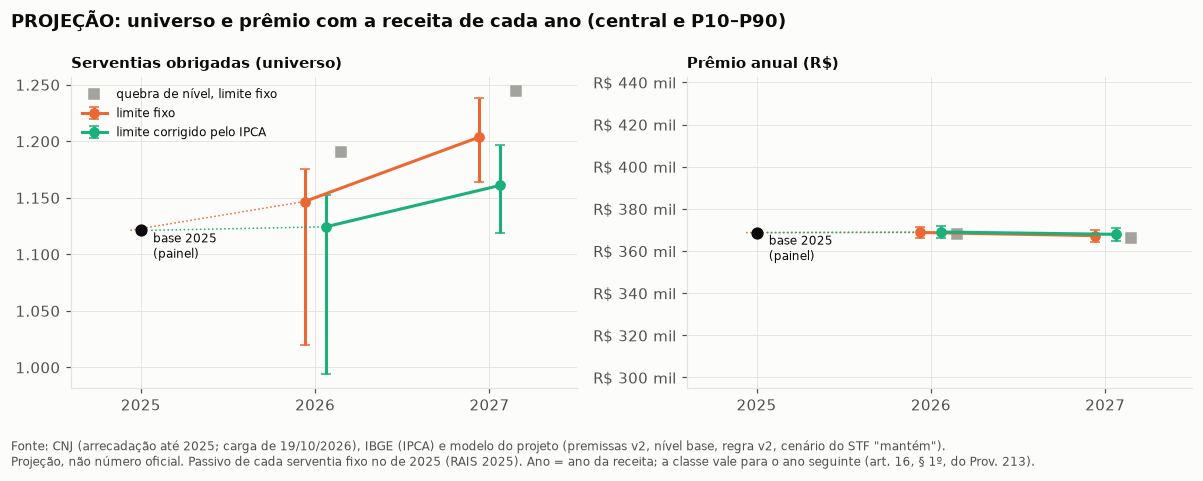

In [8]:
sc = cfg["classificacao"]["subida"]
info = cl.info_serventias(sv)
painel1 = cl.painel_subida(media, maximo, info, range(sc["primeiro_ano"], ano_b + 1), L)
painel2 = cl.painel_subida(media, maximo, info, range(sc["primeiro_ano"], ano_b + 1), L, horizonte=2)
r05 = {ano_b + 1: cl.prever_subidas(painel1, cl.casos_subida(media, maximo, info, ano_b + 1, L, 1, com_resposta=False), 1),
       ano_b + 2: cl.prever_subidas(painel2, cl.casos_subida(media, maximo, info, ano_b + 2, L, 2, com_resposta=False), 2)}
pri = proj[(proj.variante == "tendência do T2 (principal)") & (proj.medida == "subidas")].set_index(["ano", "cenario_limite"])
comp05 = pd.DataFrame([{"ano": a, "05b: floresta recalibrada (principal do 05b)": r["p_recal"].sum(),
                        "05b: floresta sem recalibração": r["p"].sum(),
                        "07: projeção, limite fixo": pri.loc[(a, "limite fixo"), "central"],
                        "07: P10 a P90": f"{g.num(pri.loc[(a, 'limite fixo'), 'p10'])} a {g.num(pri.loc[(a, 'limite fixo'), 'p90'])}"}
                       for a, r in r05.items()])
display(g.tabela(comp05, {c: "num1" for c in comp05.columns[1:4]}))

fig, axs = plt.subplots(1, 2, figsize=(11, 3.9))
cores = {"limite fixo": g.CORES[1], "limite corrigido pelo IPCA": g.CORES[2]}
for ax, m, rot in [(axs[0], "n_universo", "Serventias obrigadas (universo)"), (axs[1], "mercado_premio_emitido", "Prêmio anual (R$)")]:
    for k, (cen_lim, cor) in enumerate(cores.items()):
        r = proj[(proj.variante == "tendência do T2 (principal)") & (proj.medida == m) & (proj.cenario_limite == cen_lim)]
        xs = np.array([0] + [a - ano_b for a in r.ano]) + (k - 0.5) * 0.12
        ax.errorbar(xs[1:], r.central, yerr=[r.central - r.p10, r.p90 - r.central], fmt="o-", color=cor, capsize=3, label=cen_lim)
        ax.plot([xs[0], xs[1]], [base[m], r.central.iloc[0]], color=cor, linestyle=":", linewidth=1)
    q_ = proj[(proj.variante != "tendência do T2 (principal)") & (proj.medida == m) & (proj.cenario_limite == "limite fixo")]
    ax.plot([a - ano_b + 0.15 for a in q_.ano], q_.central, "s", color=g.CINZA, label="quebra de nível, limite fixo")
    ax.plot(0, base[m], "o", color=g.TEXTO, markersize=7)
    ax.annotate("base 2025\n(painel)", (0, base[m]), xytext=(8, -18), textcoords="offset points", fontsize=8)
    ax.set_xticks([0, 1, 2], [str(ano_b), str(ano_b + 1), str(ano_b + 2)])
    ax.set_xlim(-0.4, 2.5)
    if m.startswith("mercado"):
        ax.set_ylim(base[m] * 0.8, base[m] * 1.2)     # ±20% da base: a variação real é pequena
    ax.set_title(rot, fontsize=10)
    (g.eixo_reais if m.startswith("mercado") else g.eixo_num)(ax)
axs[0].legend(loc="upper left", fontsize=8)
fig.suptitle("PROJEÇÃO: universo e prêmio com a receita de cada ano (central e P10–P90)", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
g.nota(fig, "Fonte: CNJ (arrecadação até 2025; carga de 19/10/2026), IBGE (IPCA) e modelo do projeto (premissas v2, nível base, regra v2, "
            "cenário do STF \"mantém\").\nProjeção, não número oficial. Passivo de cada serventia fixo no de 2025 (RAIS 2025). Ano = ano da "
            "receita; a classe vale para o ano seguinte (art. 16, § 1º, do Prov. 213).")
g.salvar(fig, "07_projecao_universo_premio")
plt.show()

**Como ler.** Em cada célula: o central e, entre parênteses, a faixa P10–P90. A coluna "base 2025" é o painel. No gráfico, o eixo do prêmio vai de −20% a +20% da base, para não exagerar diferenças pequenas.

**O que encontramos (variante principal).**
- **Universo de obrigadas:** de 1.121 para **1.147 em 2026** (faixa de 1.020 a 1.175) e **1.204 em 2027** (1.164 a 1.238) com o limite fixo, **+7% em dois anos**. Com o limite corrigido pelo IPCA, o crescimento cai para 1.124 e 1.161 (+4%), porque o limite sobe 4,6% ao ano e a arrecadação, pela tendência, cerca de 7%.
- **Subidas e descidas:** em 2026, 78 subidas e 41 descidas; até 2027, 147 subidas e 32 descidas. De 32 a 42 subidas ficam até 10% acima do limite: pela regra dos dois ciclos (§ 3º), só valeriam um ano depois.
- **O prêmio quase não muda: R$ 368,8 mil em 2026 e R$ 367,3 mil em 2027** (base: R$ 368,7 mil), com faixa de ±1%. São três motivos: (1) o passivo de cada serventia fica o de 2025; (2) quem entra no universo é pequeno, perto do limite e com poucos empregados (o passivo das obrigadas sobe só 1%); (3) **51 serventias em 2026 e 98 até 2027** passam da Classe 2 para a 3, onde a chance de déficit e a parte descoberta são menores (D-011), o que reduz o déficit delas.
- **Com a quebra de nível (sensibilidade):** 1.190 obrigadas em 2026 e 1.244 em 2027 (+11%), com o prêmio ainda perto de R$ 366 a 368 mil.
- **Comparação com o 05b:** este notebook projeta **78 subidas em 2026** (faixa de 19 a 104) e **147 até 2027**. O 05b dá 145 e 210 com a recalibração e 105 e 173 sem ela. A diferença vem do crescimento: a tendência do T2 supõe +7% em 2026, enquanto a floresta do 05b olha o crescimento recente de cada serventia, que foi forte em 2025. Com a quebra, as subidas sobem para 117 e 190, perto do 05b. O teste no passado (seção 5) mostra que este método também subestima as subidas, como o 05b. **Leitura prudente:** de 80 a 145 subidas em 2026.

**O que significa para o Prov. 227.** O **número de cartórios obrigados cresce** com a arrecadação, de 4% a 11% até 2027, dependendo da correção do limite e do ritmo de crescimento. O **mercado em reais**, com os salários de 2025, fica praticamente igual: quem entra é pequeno. O que pode mudar o prêmio de verdade são as suposições do notebook 08 (taxa e adesão), não o crescimento do universo. A correção do limite pela inflação, que a norma já prevê, segura o crescimento do universo.

**Limitações.**
- **Passivo em valores de 2025.** Com reajuste de salário e mais tempo de casa, o passivo nominal cresceria; o prêmio desta projeção está em "reais de 2025" do passivo.
- A situação jurídica (provida ou vaga) fica a de hoje, e a vacância não muda (notebook 05c).
- A correção do limite usa a inflação passada no lugar da futura, e a data da primeira correção é uma suposição.
- As faixas são aproximadas (seção 5): a do crescimento de MG vem de só 5 origens.

## 7. Entrega: desenho da `gold.analise_previsao`

**O que é.** A tabela que o pipeline vai gravar na Etapa 2, para o painel mostrar a projeção, sempre com o rótulo **"projeção"**. Uma linha por bloco, período, variante, cenário do limite e medida, com a faixa:
- **bloco `arrecadacao_mg`:** cada semestre de 2026 e 2027, nas variantes principal, SARIMA, referência, sem saltos e com quebra, com o 2026-1 realizado na coluna `realizado` (incompleto na regra atual; sem saltos e completado nas outras);
- **bloco `mercado`:** 2026 e 2027, por variante e cenário do limite, para as 11 medidas da seção 6.

A função é `previsao.tabela_previsao` (`src/analise/previsao.py`, com teste em `tests/test_analise_previsao.py`).

In [9]:
arr = []
for nome, f, real in [("tendência do T2, regra atual (principal)", faixas[pv.PRINCIPAL], y_tudo[ULT]),
                      ("SARIMA, regra atual (comparação)", faixas[SARIMA], y_tudo[ULT]),
                      ("referência: repete o último semestre", faixas[pv.REFERENCIA], y_tudo[ULT]),
                      ("tendência do T2, sem saltos grosseiros", f_ss, y_c[ULT]),
                      (f"quebra de nível em {pc['quebra']}, sem saltos e com o {ULT} completado", f_q, np.nan)]:
    for periodo, r in f.iterrows():
        arr.append({"periodo": periodo, "variante": nome, "p10": r.p10, "central": r.central, "p90": r.p90,
                    "realizado": real if periodo == ULT else np.nan})
analise_previsao = pv.tabela_previsao(pd.DataFrame(arr), proj)
print(f"gold.analise_previsao (desenho): {len(analise_previsao)} linhas ({(analise_previsao.bloco == 'arrecadacao_mg').sum()} da "
      f"arrecadação e {(analise_previsao.bloco == 'mercado').sum()} do mercado); colunas: {', '.join(analise_previsao.columns)}.")
display(analise_previsao[(analise_previsao.medida.isin(["arrecadacao_semestral", "n_universo", "mercado_premio_emitido"]))
                         & analise_previsao.variante.str.contains("principal")].head(12))

gold.analise_previsao (desenho): 107 linhas (19 da arrecadação e 88 do mercado); colunas: bloco, periodo, variante, cenario_limite, medida, p10, central, p90, realizado, rotulo.


,bloco,periodo,variante,cenario_limite,medida,p10,central,p90,realizado,rotulo
0,arrecadacao_mg,2026-1,"tendência do T2, regra atual (principal)",—,arrecadacao_semestral,2.387599e+09,2.737137e+09,2.940874e+09,3.202268e+09,projeção
1,arrecadacao_mg,2026-2,"tendência do T2, regra atual (principal)",—,arrecadacao_semestral,2.774567e+09,3.180756e+09,3.417514e+09,NaN,projeção
2,arrecadacao_mg,2027-1,"tendência do T2, regra atual (principal)",—,arrecadacao_semestral,2.705782e+09,3.101901e+09,3.332790e+09,NaN,projeção
3,arrecadacao_mg,2027-2,"tendência do T2, regra atual (principal)",—,arrecadacao_semestral,3.144320e+09,3.604640e+09,3.872949e+09,NaN,projeção
25,mercado,2026,tendência do T2 (principal),limite fixo,n_universo,1.019683e+03,1.146746e+03,1.175202e+03,NaN,projeção
29,mercado,2026,tendência do T2 (principal),limite fixo,mercado_premio_emitido,3.661499e+05,3.687815e+05,3.715039e+05,NaN,projeção
36,mercado,2026,tendência do T2 (principal),limite corrigido pelo IPCA,n_universo,9.942632e+02,1.124357e+03,1.152943e+03,NaN,projeção
40,mercado,2026,tendência do T2 (principal),limite corrigido pelo IPCA,mercado_premio_emitido,3.662863e+05,3.689992e+05,3.718864e+05,NaN,projeção
69,mercado,2027,tendência do T2 (principal),limite fixo,n_universo,1.163907e+03,1.203678e+03,1.238223e+03,NaN,projeção
73,mercado,2027,tendência do T2 (principal),limite fixo,mercado_premio_emitido,3.642365e+05,3.672910e+05,3.700744e+05,NaN,projeção


## 8. Resumo dos achados

1. **A tendência do T2 se confirma** (MAPE de 7,4% contra 14,8% da referência; viés de −2,1% em 2024–25): MG arrecada **R$ 5,92 bi em 2026** (+7,3%) e **R$ 6,71 bi em 2027**, com faixa P10–P90 de cerca de −13% a +7%. Valores nominais, rotulados como projeção.
2. **O "2026-1 acima do P90" do T2 é, em grande parte, erro de declaração:** três semestres com saltos grosseiros (serventias 059816, 042986 e 046219) somam R$ 360 mi. Sem eles e com o 2026-1 completado, o semestre fica dentro da faixa (R$ 2,90 bi; faixa de R$ 2,38 a 2,93 bi).
3. **Não há evidência estatística de quebra de nível em 2025-2** (+7,6%, valor-p 0,37), mas a arrecadação limpa acelerou (de +14% a +21% sobre o ano anterior desde 2024-2). O teste deve ser refeito com o 2026-1 completo e com o 2026-2.
4. **O universo de obrigadas cresce de 4% a 11% até 2027:** 1.204 obrigadas em 2027 com o limite fixo, 1.161 com o limite corrigido pelo IPCA e 1.244 com a quebra (base: 1.121).
5. **O prêmio fica em torno de R$ 367 mil** em todas as variantes (±1%), com o passivo de 2025: quem entra é pequeno, e parte das obrigadas passa para a Classe 3, que tem déficit menor.
6. **A projeção por serventia passou no teste no passado** (erro de 36 a 40 serventias contra 99 a 204 da referência), mas a faixa é estreita demais, e as subidas saem subestimadas, como no 05b.

**Para o cálculo do painel:** nada aqui muda os 10 números. Para o autor:
- (a) decidir a regra do salto grosseiro: com os saltos de 2025-2 e 2026-1, ela passou a mexer no total de MG (R$ 161 mi e R$ 330 mi);
- (b) refazer este notebook com o 2026-1 completo, depois de uma coleta e uma carga novas (gratuitas, só a pedido do autor);
- (c) se o painel vai mostrar a projeção com o limite fixo, com o corrigido ou com os dois (a norma prevê a correção, mas ainda não houve divulgação de valores);
- (d) o MASE do T2 estava com o divisor errado (sem efeito na escolha do método).

> **Atualização (2026-10-28, notebook 10, melhorias M3, M4 e M5).** (M3 b) No teste desde 2012, o SARIMA erra menos que a tendência; na janela recente (a do T2), a tendência continua melhor e segue como principal. (M3 c) A faixa da arrecadação cobriu 86% no passado; a da contagem acima do limite, só 27%, e a versão calibrada pelos erros passados cobriu 60%. (M4) O desvio condicionado não melhora a contagem de subidas: o erro vem da previsão de MG (com o fator real, cai pela metade). (M5) O passivo sobe 14,6% em 2026 e 28,5% em 2027; com ele, o prêmio projetado sobe na mesma proporção. Refazer a previsão com o 2026-1 de uma coleta nova (M3 a) ficou de fora: o autor decidiu ficar com os dados de 17 e 18/10 (D-046). Este notebook não mudou; os números estão no `notebooks/10_melhorias_confianca.ipynb`, seções 6 a 8, e no achado 8 do 09.

> **Atualização (2026-10-28, D-046): premissas v3.** As saídas deste notebook são da carga com as premissas v2. Desde a D-046, a chance de déficit e a parte descoberta vêm da capacidade de pagar do titular (M1, notebook 10), e não mais de suposição. Os números 1 a 5 e o 10 não mudaram; o déficit, a IS e o prêmio caíram 7,5% (prêmio de R$ 368,7 mil para R$ 341,1 mil), e a contagem "com déficit" foi de ≈ 486 para ≈ 148. O que este notebook diz sobre dados, classes, passivo e universo continua valendo; os valores de déficit e prêmio atuais estão no `notebooks/09_conclusoes_lacunas.ipynb`. A D-046 também manteve o valor declarado nos semestres com salto grosseiro (com aviso no pipeline e sensibilidade "sem os saltos") e deixou os dados como os de 17 e 18/10.